# Speech Emotion Recognition on CREMA-D
**Pipeline:** select clips → speaker-independent split → low-pass filter → feature extraction → 5 classifiers → evaluation.

This notebook is both the experiment record and a learning guide. Each section explains the idea first, then runs the code.
Heavy grid searches were run once by the scripts in `src/`; their results are loaded from `results/*.csv` so the notebook runs in about a minute.

**Task:** classify each clip into one of 6 emotions: Anger, Disgust, Fear, Happy, Neutral, Sad.

In [1]:
import sys, warnings; sys.path.insert(0, "src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from common import *
pd.set_option("display.width", 140)

## 1. The data
Each filename encodes its labels: `1001_DFA_ANG_XX.wav` = actor 1001, sentence DFA, emotion ANG, intensity unspecified.
Audio is **digital**: a sequence of numbers (samples). Here the sampling rate is 16,000 samples per second, so the highest frequency we can represent is 8,000 Hz (the *Nyquist limit*, half the sampling rate).

In [2]:
df = load_table()
print(len(df), "clips |", df.actor.nunique(), "actors |", df.sentence.nunique(), "sentences")
print(df.emotion.value_counts().to_string())
print("intensity levels:", df.level.value_counts().to_dict(), "(82% unspecified, so intensity is not usable as a label)")
df.head()

7442 clips | 91 actors | 12 sentences
emotion
ANG    1271
DIS    1271
FEA    1271
HAP    1271
SAD    1271
NEU    1087
intensity levels: {'XX': 6077, 'HI': 455, 'LO': 455, 'MD': 455} (82% unspecified, so intensity is not usable as a label)


,path,actor,sentence,emotion,level
0,/home/awwab/personal/ml-cep/data_src/Sentiment...,1001,DFA,ANG,XX
1,/home/awwab/personal/ml-cep/data_src/Sentiment...,1001,DFA,DIS,XX
2,/home/awwab/personal/ml-cep/data_src/Sentiment...,1001,DFA,FEA,XX
3,/home/awwab/personal/ml-cep/data_src/Sentiment...,1001,DFA,HAP,XX
4,/home/awwab/personal/ml-cep/data_src/Sentiment...,1001,DFA,NEU,XX


### Data-quality check: silent clips
A classifier cannot learn from silence, and some feature statistics (e.g. skewness) are undefined for an all-zero signal. We scan every clip for its peak amplitude.

In [3]:
peaks = np.array([np.abs(load_audio(p)).max() for p in df.path])
silent = df[peaks == 0]
print("completely silent clips:", silent.path.map(lambda p: p.split('/')[-1]).tolist())
print("excluded in all experiments:", EXCLUDE)

completely silent clips: ['1076_MTI_SAD_XX.wav']
excluded in all experiments: {'1076_MTI_SAD_XX'}


## 2. The noise: an added 7.5 kHz tone
The folder is called `NoiseAudioWAV`. Plotting a spectrogram (frequency vs. time) shows a constant bright line at 7.5 kHz.
We verify that it is present in every clip using the FFT (Fourier transform), which splits a signal into its frequencies.

In [4]:
sample = df.sample(300, random_state=0)
peak_hz, share = [], []
for p in sample.path:
    y = load_audio(p); mag = np.abs(np.fft.rfft(y*np.hanning(len(y)))); f = np.fft.rfftfreq(len(y), 1/SR)
    peak_hz.append(f[mag.argmax()]); b = (f>7400)&(f<7600); share.append((mag[b]**2).sum()/(mag**2).sum())
peak_hz = np.array(peak_hz)
print(f"strongest frequency: median {np.median(peak_hz):.0f} Hz; within 7.4-7.6 kHz in {np.mean((peak_hz>7400)&(peak_hz<7600)):.0%} of clips")
print(f"median share of total energy in that band: {np.median(share):.0%}")

strongest frequency: median 7500 Hz; within 7.4-7.6 kHz in 100% of clips
median share of total energy in that band: 95%


### Low-pass filter
A **low-pass filter** keeps frequencies below a cutoff and removes those above. We use a 5th-order *Butterworth* filter applied forwards and backwards (`filtfilt`) so the signal is not shifted in time.
A Butterworth filter does not cut sharply: it rolls off gradually. That is why a 7 kHz cutoff would be a poor choice for a tone at 7.5 kHz, and why we compare 3, 4 and 5.5 kHz.
The figure shows the clip before and after, and the filter responses against the tone.

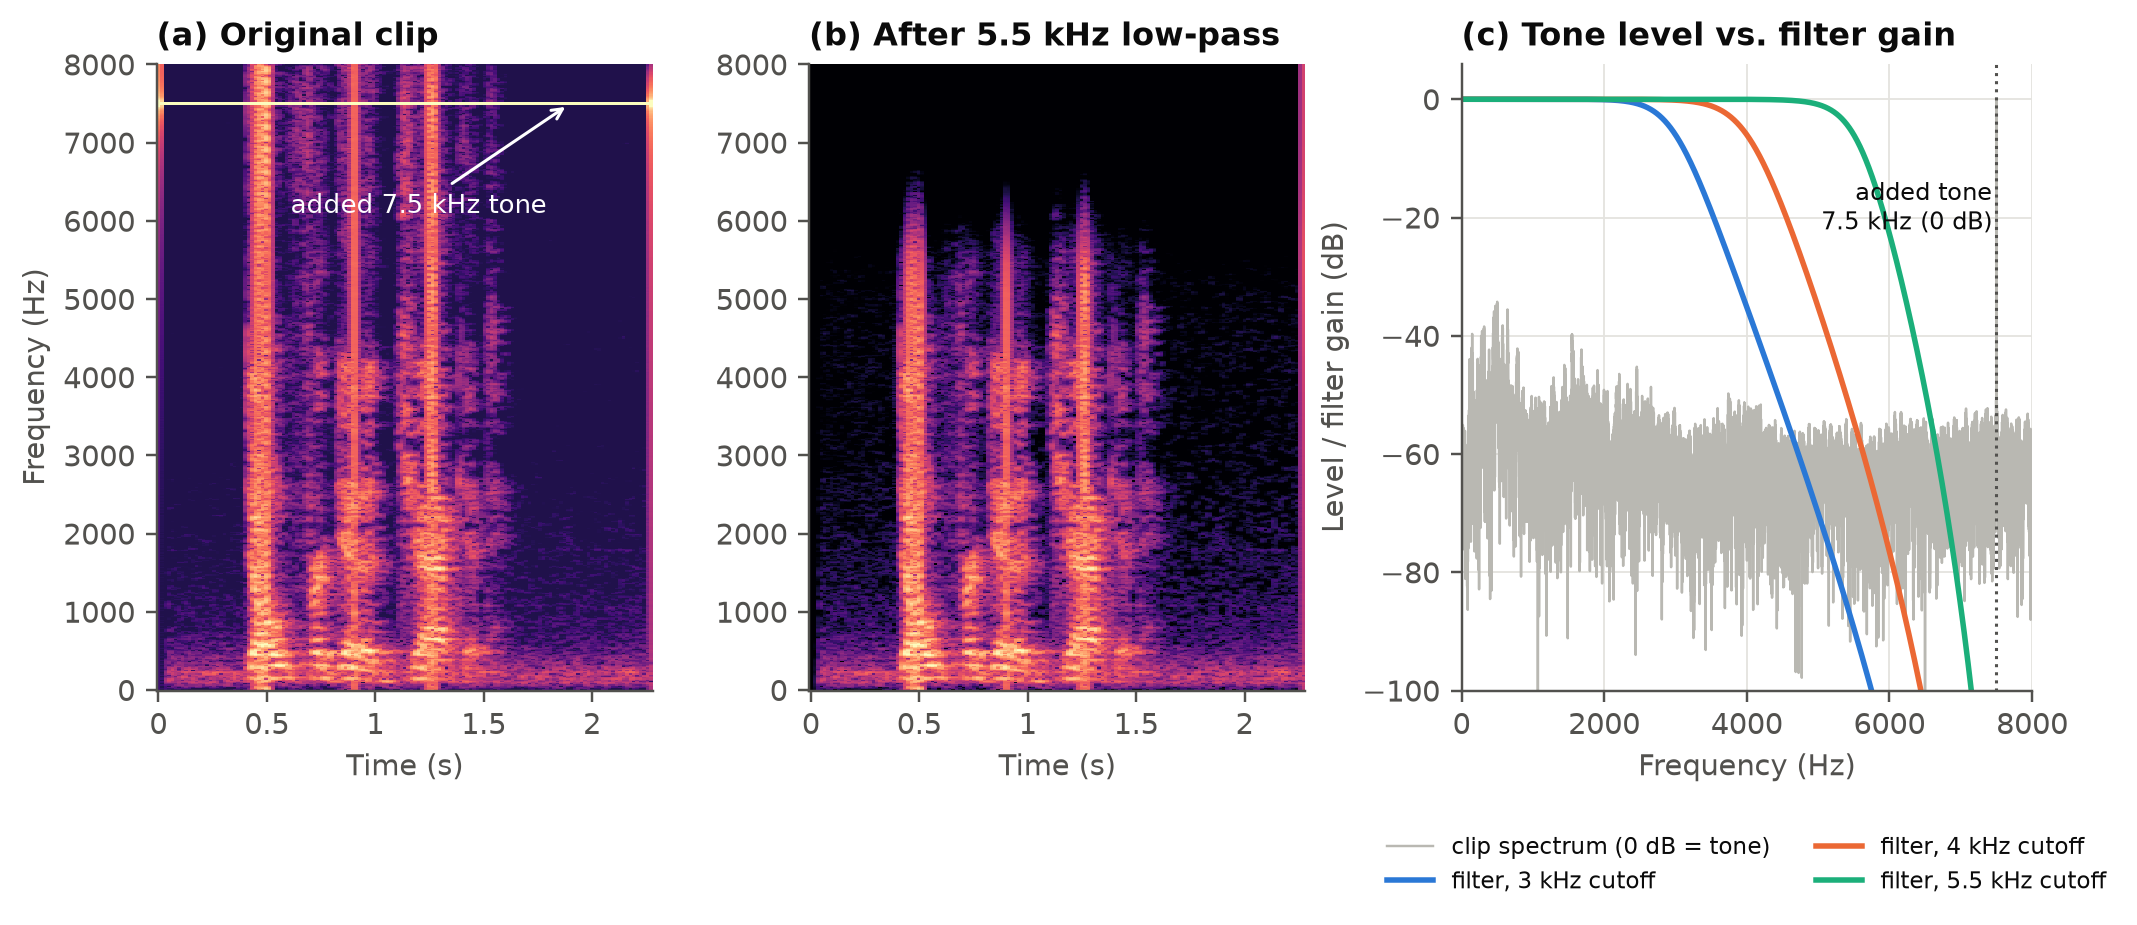

In [5]:
display(Image("report/figures/fig_noise.png"))

## 3. Speaker-independent split
If an actor's clips appear in both training and test sets, a model can learn *who is speaking* rather than *what emotion*, which inflates test accuracy.
So we assign whole **actors** to train / validation / test (63 / 14 / 14), with no overlap.

In [6]:
df = speaker_split(df)
print(df.groupby("split").agg(clips=("path","size"), actors=("actor","nunique")))
sets = {s: set(g.actor) for s, g in df.groupby("split")}
assert not (sets["train"]&sets["val"] or sets["train"]&sets["test"] or sets["val"]&sets["test"])
print("OK: no actor appears in more than one split")
pd.crosstab(df.split, df.emotion)

       clips  actors
split               
test    1142      14
train   5158      63
val     1142      14
OK: no actor appears in more than one split


emotion,ANG,DIS,FEA,HAP,NEU,SAD
split,,,,,,
test,195,195,195,195,167,195
train,881,881,881,881,753,881
val,195,195,195,195,167,195


## 4. Features: from a clip to a fixed-length vector
Clips differ in length, but classifiers need equal-length inputs. Two steps:
1. **Frame the signal:** 64 ms windows every 16 ms (a 2.5 s clip gives about 160 frames); compute features per frame.
2. **Pool over time:** summarize each per-frame feature by its **mean and standard deviation**. The result has the same length for every clip.

| Feature | Measures | Why it can separate emotions |
|---|---|---|
| FFT spectrum | average energy per frequency band | angry/happy speech has more high-frequency energy |
| Mel-spectrogram | energy per band on the perceptual (mel) scale, in dB | keeps loudness and spectral shape |
| MFCC | the overall *shape* of the spectrum | reflects vocal-tract configuration and effort |
| Chroma | energy in the 12 pitch classes | crude pitch information |
| Spectral centroid | centre of mass of the spectrum (brightness) | tense speech is brighter |
| Spectral bandwidth | spread of energy around the centroid | strained speech is wider |
| Spectral contrast | peak-to-valley dB difference per band | voiced vs breathy/noisy sound |

In [7]:
from features import extract, HOP
y = lowpass(load_audio(df.path.iloc[0]), 5500)
print(f"one clip: {len(y)} samples = {len(y)/SR:.2f} s -> {1+len(y)//HOP} frames")
tot = 0
for g, v in extract(y).items(): print(f"  {g:10s} {v.shape[0]:4d} numbers"); tot += v.shape[0]
print("  total", tot, "| 1-second clip also gives", sum(v.shape[0] for v in extract(y[:SR]).values()))

one clip: 36409 samples = 2.28 s -> 143 frames


  mfcc         40 numbers
  mel         128 numbers
  chroma       24 numbers
  centroid      2 numbers
  bandwidth     2 numbers
  contrast     14 numbers
  fft          32 numbers
  total 242 | 1-second clip also gives 242


### Bicoherence
The ordinary spectrum asks *how much energy is at each frequency*. **Bicoherence** asks whether frequencies *f1, f2 and f1+f2 are phase-locked*, which indicates nonlinear effects such as irregular vocal-fold vibration.
We average the triple product `X(f1)·X(f2)·conj(X(f1+f2))` over frames, normalise, and summarise the resulting 2-D map by the **mean, variance, skewness and kurtosis of its magnitude and phase** (8 numbers).

In [8]:
from bicoherence import bicoherence_stats
names = [f"{c}_{s}" for c in ("mag","phase") for s in ("mean","var","skew","kurt")]
for emo in ["ANG","SAD"]:
    p = df[(df.actor==1001)&(df.sentence=="DFA")&(df.emotion==emo)].path.iloc[0]
    print(emo, dict(zip(names, bicoherence_stats(lowpass(load_audio(p),5500)).round(2))))

ANG {'mag_mean': np.float64(0.2), 'mag_var': np.float64(0.02), 'mag_skew': np.float64(0.46), 'mag_kurt': np.float64(-0.42), 'phase_mean': np.float64(0.02), 'phase_var': np.float64(2.76), 'phase_skew': np.float64(0.04), 'phase_kurt': np.float64(-0.84)}
SAD {'mag_mean': np.float64(0.14), 'mag_var': np.float64(0.01), 'mag_skew': np.float64(0.84), 'mag_kurt': np.float64(0.11), 'phase_mean': np.float64(0.4), 'phase_var': np.float64(3.53), 'phase_skew': np.float64(-0.41), 'phase_kurt': np.float64(-1.17)}


## 5. Classifiers
Five scikit-learn models, each behind a `StandardScaler` (fit on training data only, so no test statistics leak in).
Hyperparameters were chosen on the **validation** actors; the **test** actors were used once, for the final score.
We report accuracy and **macro-F1** (the unweighted mean of per-class F1, robust to Neutral having fewer clips).

Below we re-fit the two best models with their selected hyperparameters to show the mechanics.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from train_eval import load
X, y, split = load("lp5500")
tr, te = split=="train", split=="test"
print("train", X[tr].shape, "test", X[te].shape)
for name, clf in [("Logistic regression", LogisticRegression(C=1, max_iter=3000)), ("SVM (RBF)", SVC(C=100, gamma=0.001))]:
    m = make_pipeline(StandardScaler(), clf).fit(X[tr], y[tr])
    print("\n" + name); print(classification_report(y[te], m.predict(X[te]), digits=3))

train (5157, 242) test (1142, 242)



Logistic regression
              precision    recall  f1-score   support

         ANG      0.650     0.790     0.713       195
         DIS      0.462     0.436     0.449       195
         FEA      0.500     0.533     0.516       195
         HAP      0.492     0.472     0.482       195
         NEU      0.475     0.515     0.494       167
         SAD      0.648     0.482     0.553       195

    accuracy                          0.539      1142
   macro avg      0.538     0.538     0.534      1142
weighted avg      0.539     0.539     0.535      1142




SVM (RBF)


              precision    recall  f1-score   support

         ANG      0.643     0.805     0.715       195
         DIS      0.451     0.421     0.435       195
         FEA      0.484     0.544     0.512       195
         HAP      0.505     0.508     0.506       195
         NEU      0.497     0.473     0.485       167
         SAD      0.592     0.431     0.499       195

    accuracy                          0.532      1142
   macro avg      0.529     0.530     0.525      1142
weighted avg      0.529     0.532     0.526      1142



## 6. Results
All numbers are on the 14 held-out test actors. Chance level is 1/6 = 0.167.

### 6.1 Effect of the filter cutoff

test_acc        test_macro_f1       
model      LogReg    SVM        LogReg    SVM
features                                     
lp3000      0.513  0.522         0.509  0.517
lp4000      0.527  0.520         0.521  0.515
lp5500      0.539  0.532         0.534  0.525
lp7000      0.525  0.511         0.520  0.507
raw         0.532  0.519         0.524  0.513

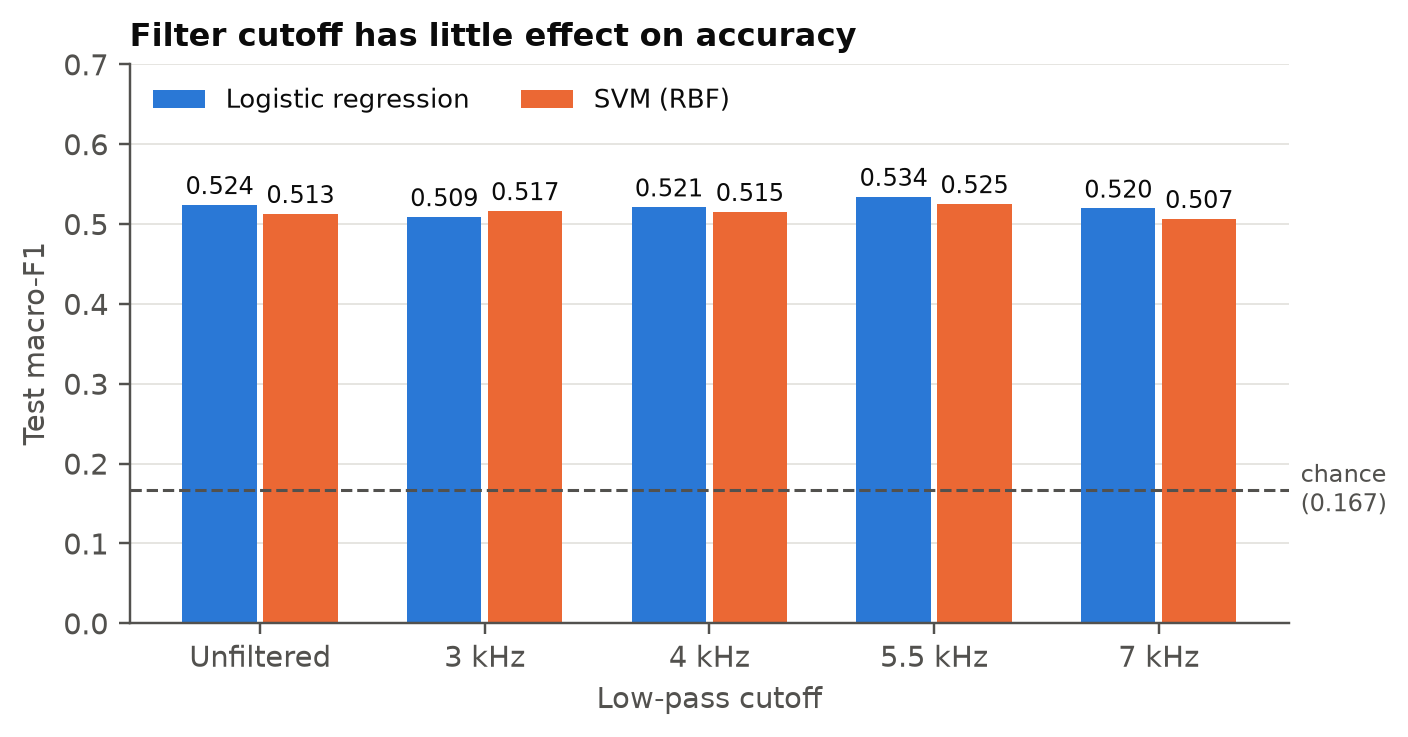

In [10]:
cut = pd.read_csv("results/cutoff_comparison.csv")
display(cut.pivot(index="features", columns="model", values=["test_acc","test_macro_f1"]).round(3))
display(Image("report/figures/fig_cutoff.png"))

All five settings (unfiltered, 3, 4, 5.5 and 7 kHz) land between 0.507 and 0.534 macro-F1; the spread is comparable to the ~1.5-point standard error on 14 test actors, so no cutoff is demonstrably better. Every cutoff removes the tone (measured attenuation: about 61 dB at 7 kHz, at least 147 dB for 5.5 kHz and below).

**How 5.5 kHz was chosen (read this honestly).** It ranked first on validation among unfiltered/3/4/5.5 kHz for both models, and also first on test. 7 kHz was added later and is nominally best on validation (mean val F1 0.511 vs 0.507), a difference far inside the noise. We kept 5.5 kHz for consistency; a strictly validation-only rule would pick 7 kHz (test F1 0.520 / 0.507) without changing any conclusion.

### 6.2 Which features matter? (single-group ablation, 5.5 kHz)

model,LogReg,SVM
group,,
mfcc,0.501,0.524
mel,0.442,0.507
fft,0.407,0.460
contrast,0.366,0.410
chroma,0.305,0.338
bico,0.275,0.322
centroid,0.272,0.288
bandwidth,0.242,0.277


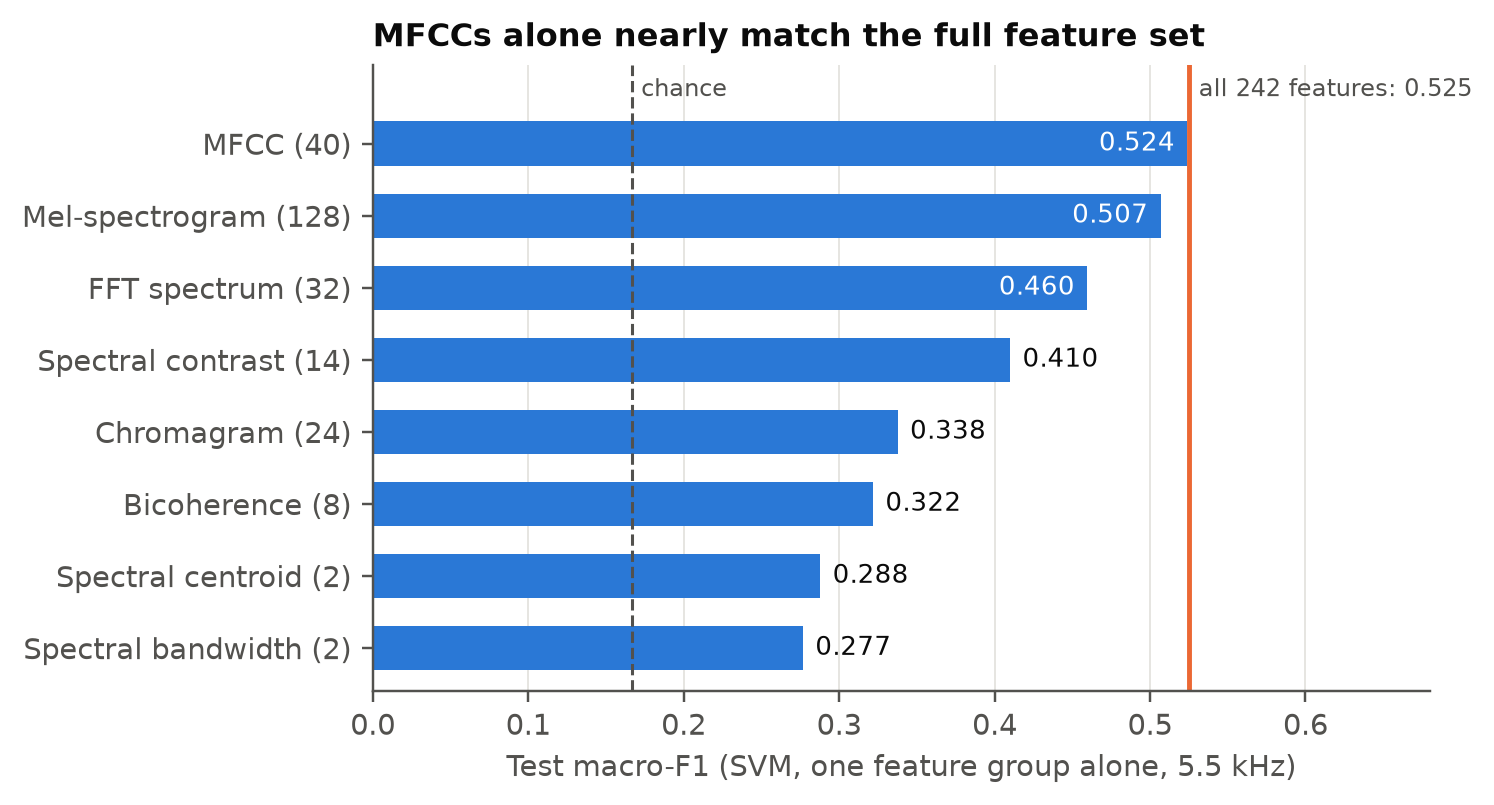

In [11]:
ab = pd.read_csv("results/ablation_single_group.csv")
display(ab.pivot(index="group", columns="model", values="test_macro_f1").round(3).sort_values("SVM", ascending=False))
display(Image("report/figures/fig_ablation.png"))

MFCCs alone (40 numbers) reach 0.524 macro-F1, the same as all 242 features (0.525). The 128-number mel-spectrogram is 1.7 points lower (within noise): MFCCs do at least as well with a third of the dimensions, which matters with ~5,000 training clips. Chroma is weak because it is designed for music. Bicoherence alone (8 numbers) reaches 0.322, about twice chance.

### 6.3 All five classifiers, with and without bicoherence (5.5 kHz)

,features,model,val_f1,test_acc,test_macro_f1,n_features
0,bico_only,LogReg,0.260,0.290,0.275,8
1,bico_only,SVM,0.303,0.327,0.322,8
2,lp5500,KNN,0.437,0.477,0.462,242
3,lp5500,LogReg,0.493,0.539,0.534,242
4,lp5500,NaiveBayes,0.337,0.425,0.373,242
5,lp5500,SVM,0.521,0.532,0.525,242
6,lp5500,NeuralNet,0.496,0.516,0.511,242
7,lp5500+bico,KNN,0.434,0.454,0.441,250
8,lp5500+bico,LogReg,0.497,0.534,0.528,250
9,lp5500+bico,NaiveBayes,0.336,0.422,0.372,250


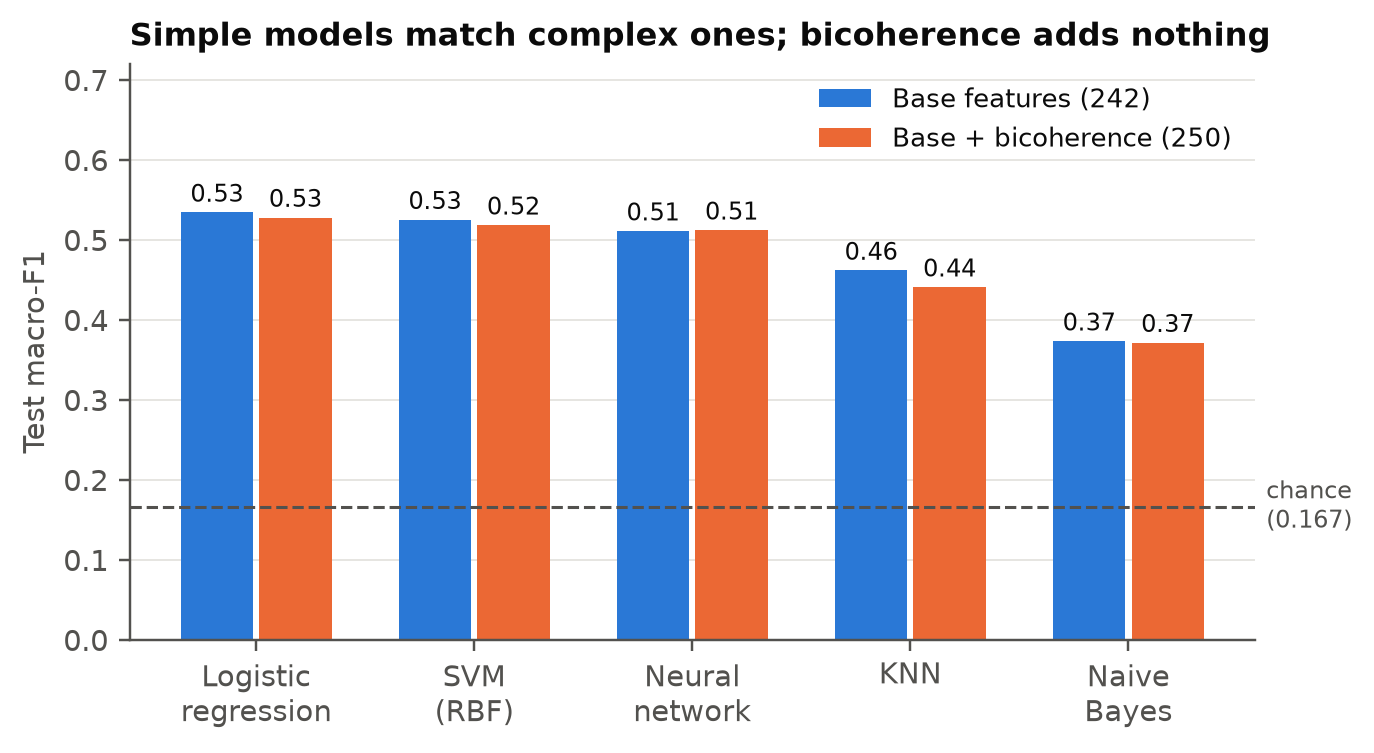

In [12]:
fin = pd.read_csv("results/final_models.csv")
display(fin.drop(columns="best_params").round(3))
display(Image("report/figures/fig_models.png"))

Bicoherence alone reaches 0.32 macro-F1 (twice chance), but adding it to the other features does not help. Logistic regression is the best model, which suggests the limiting factor is the information in the features and the amount of data, not model complexity.

### Confusion matrices

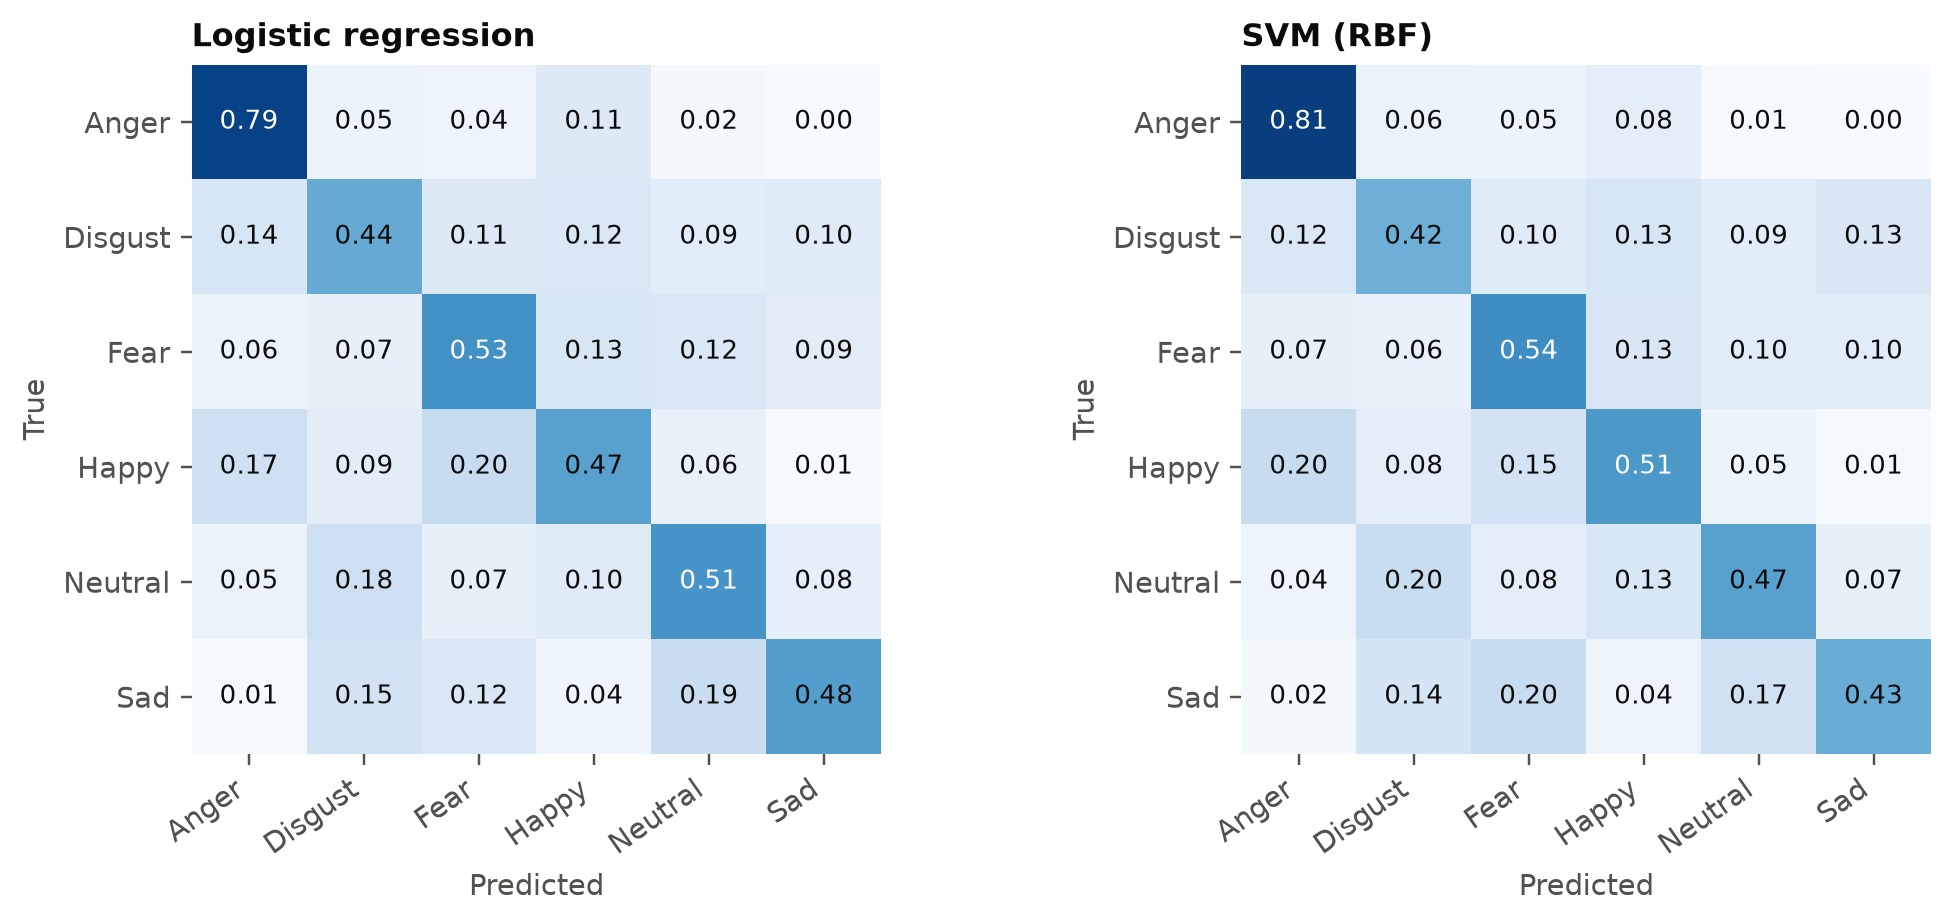

In [13]:
display(Image("report/figures/fig_confusion.png"))

Anger is recognised best (about 80% recall). The main confusions are happy↔anger/fear and sad↔neutral/fear/disgust: pairs that share *arousal* (energy level). Spectral features capture arousal well but valence (positive vs. negative) poorly.

### 6.4 Does the tone leak the label?
We predict the emotion from a single number: the tone's amplitude, and, for comparison, the loudness of the clean (filtered) speech.

In [14]:
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score
keep = ~df.path.map(lambda p: p.split("/")[-1][:-4] in EXCLUDE)
d2 = df[keep]
def tone(p):
    y = load_audio(p); mag = np.abs(np.fft.rfft(y*np.hanning(len(y))))/len(y); f = np.fft.rfftfreq(len(y),1/SR)
    return [np.log(mag[(f>7450)&(f<7550)].max()), np.log(np.abs(y).max()), np.log(np.sqrt((lowpass(y,5500)**2).mean())+1e-9)]
F = np.array(Parallel(n_jobs=10)(delayed(tone)(p) for p in d2.path))
yy = d2.emotion.to_numpy(); t_tr=(d2.split=="train").to_numpy(); t_te=(d2.split=="test").to_numpy()
for nm, c in [("tone amplitude only",[0]),("speech loudness only (filtered)",[2]),("tone + speech loudness jointly",[0,2])]:
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(F[t_tr][:,c], yy[t_tr])
    print(f"{nm:34s} test acc {accuracy_score(yy[t_te], m.predict(F[t_te][:,c])):.3f}  (chance 0.167)")
print("corr(tone amplitude, raw peak) = %.3f" % np.corrcoef(F[:,0],F[:,1])[0,1])

tone amplitude only                test acc 0.369  (chance 0.167)
speech loudness only (filtered)    test acc 0.370  (chance 0.167)
tone + speech loudness jointly     test acc 0.394  (chance 0.167)
corr(tone amplitude, raw peak) = 0.990


The tone's amplitude tracks the clip's peak level (correlation ≈ 0.99), and predicts emotion no better than the clean speech loudness does. Using both together gains only 1-2 points (within noise), so the tone carries essentially the same information as loudness. Note that loudness itself partly reflects actor and recording conditions.

**An unexplained observation.** Filtering changes the mean spectral centroid from 5,562 Hz (pulled toward the tone) to 1,144 Hz (speech only), yet the *unfiltered* centroid and bandwidth classify better than the clean ones (SVM macro-F1 0.335 vs 0.288 and 0.338 vs 0.277). We did not establish why (untested hypothesis: the fixed-level tone acts as a reference that makes the raw centroid a frame-wise energy cue). Because real recordings would not contain the tone, we treat it as an artefact to remove.

## 7. Conclusions and limitations
* Best result: **≈ 0.53 accuracy / 0.53 macro-F1** on unseen speakers (chance 0.17); logistic regression and SVM tie.
* A speaker-independent split is essential; random splits would overstate performance.
* The low-pass filter removes the added tone but does not measurably change overall accuracy; cutoffs from 3 to 7 kHz are indistinguishable within noise.
* MFCCs carry most of the signal; bicoherence adds nothing on top.
* **Limitations:** acted speech, not natural; 14 test actors give a noisy estimate (we do not repeat over several random actor splits); pooling over time discards temporal order; hyperparameter grids are small; the ablation uses a single split; the 5.5 kHz cutoff was carried forward after a sweep in which it also had the best test score, so a small selection effect cannot be excluded.